### Threading

The **GIL - Global Interpreter Lock** is a mutex - like a lock, which commonly between Python user. In this configuration:
- Only one thread can execute **Python bytecode** at any moment
- The GIL is released periodically (every ~5 ms by default in recent versions), during I/O operations, and when calling certain C extension functions that explicitly release it.
- Results -> **True parallelism for CPU-bound pure-Python code is impossible** in standard builds.

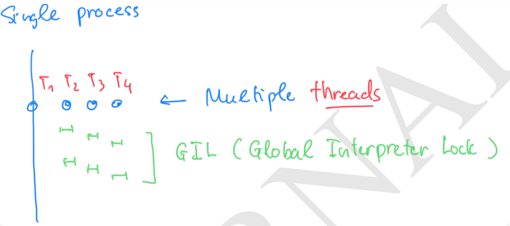

**Threads** refers to the use of **OS-level threads** (native threads managed by the operating system) to achieve concurrency within a single process.

**Life cycle**

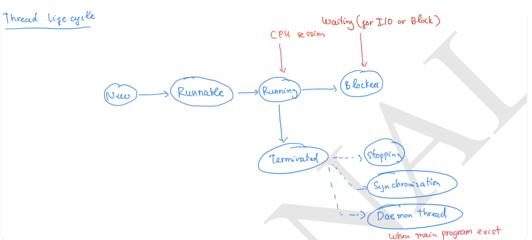

Where States:
- New: Thread object is created, `start()` not yet called
- Runnable: After `start()`, waiting for CPU time
- Running: Currently executing `run()`
- Blocked/Waiting: Waiting for I/O, lock, sleep, join
- Terminated: `run()` completed or exception occurred

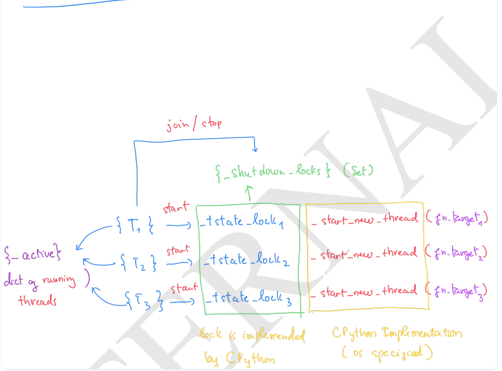

```python
import threading
import time

def worker(name):
    print(f"Thread {name} starting")
    time.sleep(1)
    print(f"Thread {name} finished")

# Create threads
t1 = threading.Thread(target=worker, args=("T1",))
t2 = threading.Thread(target=worker, args=("T2",))

# Start threads
t1.start()
t2.start()

# Wait for completion
t1.join()
t2.join()
print("All done!")

## When Threading is Excellent (Even with GIL)

- **I/O-bound work** where most time is spent waiting (network, disk, database, subprocesses, user input)
    - Threads can make progress while others wait → effective concurrency
    - Many C extensions release the GIL during blocking operations (socket.recv, file.read, numpy ops, cryptography calls, etc.)
- **Mixed workloads** where part is I/O and part is fast C-extension CPU work
- **Interfacing with blocking libraries** that don't have good async equivalents
- **Simpler mental model** than asyncio for medium concurrency (dozens to low hundreds of tasks)
- **GUI applications** (Tkinter, PyQt, wxPython)

## When Threading is Disappointing (GIL Bottleneck)

- Pure-Python CPU-bound loops (numerical calculations, string processing, crypto implemented in Python, recursive algorithms, etc.)
- Many threads doing heavy pure-Python work → performance can be worse than single-threaded due to GIL contention + context switching overhead

### ThreadPool

ThreadPool helps manage and reuse threads efficiently:

```python
from multiprocessing.pool import ThreadPool

def work(x):
    return x * x

# Create pool with 4 worker threads
pool = ThreadPool(processes=4)

# Map function to list
results = pool.map(work, [1, 2, 3, 4, 5])
print(results)  # [1, 4, 9, 16, 25]

# Cleanup
pool.close()
pool.join()

### Thread and Scope

```python
# Threads Share Global Scope:
import threading
import time

count = 0  # Global variable

def try_count(name):
    global count
    count += 1
    time.sleep(0.1)
    print(f"Thread {name}: count = {count}")

t1 = threading.Thread(target=try_count, args=("T1",))
t2 = threading.Thread(target=try_count, args=("T2",))

t1.start(); t2.start()
t1.join(); t2.join()
# Output: Both threads may see count = 2 (race condition!)

```python
# Thread-Safe with Lock
import threading

count = 0
lock = threading.Lock()

def try_count(name):
    global count
    with lock:  # Acquire lock
        count += 1
        print(f"Thread {name}: count = {count}")
    # Lock is automatically released

```python
# Thread Local Storage
import threading

thread_local = threading.local()

def worker(name):
    thread_local.count = 0
    thread_local.count += 1
    print(f"Thread {name}: count = {thread_local.count}")

t1 = threading.Thread(target=worker, args=("T1",))
t2 = threading.Thread(target=worker, args=("T2",))

t1.start(); t2.start()
# Output: Each thread has its own count = 1